In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [53]:
import numpy as np

def hierarchical_bottom_up_optimized(X, k=2):
    n_samples = X.shape[0]
    
    diff = X[:, np.newaxis, :] - X[np.newaxis, :, :]
    dist_matrix = np.sum(diff ** 2, axis=2).astype(float)
    
    np.fill_diagonal(dist_matrix, float('inf'))
    
    clusters = {i: [i] for i in range(n_samples)}
    active_clusters = set(range(n_samples))
    
    while len(active_clusters) > k:
        min_idx = np.argmin(dist_matrix)
        merge_i, merge_j = np.unravel_index(min_idx, dist_matrix.shape)
        
        if merge_i > merge_j:
            merge_i, merge_j = merge_j, merge_i
            
        clusters[merge_i].extend(clusters[merge_j])
        del clusters[merge_j] 
        
        for c in active_clusters:
            if c != merge_i and c != merge_j:
                new_dist = min(dist_matrix[merge_i, c], dist_matrix[merge_j, c])
                dist_matrix[merge_i, c] = new_dist
                dist_matrix[c, merge_i] = new_dist
                
        dist_matrix[merge_j, :] = float('inf')
        dist_matrix[:, merge_j] = float('inf')
        active_clusters.remove(merge_j)
        
    assigned_cluster = np.zeros(n_samples, dtype=int)
    final_clusters = list(clusters.values())
    
    for i, cluster in enumerate(final_clusters):
        for point in cluster:
            assigned_cluster[point] = i
            
    return assigned_cluster, final_clusters

In [54]:
from sklearn.datasets import make_classification

X, y = make_classification(
    n_samples=100,
    n_classes= 2,
    n_features=2, 
    n_redundant= 0,
    random_state=42,
    n_clusters_per_class=1,
    n_informative=2,
    class_sep=2
)

In [55]:
print(type(X))
print(type(y))
print(X.shape)
print(y.shape)

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
(100, 2)
(100,)


In [56]:
df = pd.DataFrame(X, columns=['f1', 'f2'])
df['Target'] = y
df.head()

,f1,f2,Target
0,2.228312,-1.757178,0
1,1.698409,-2.380295,0
2,3.548817,3.502258,1
3,1.573579,-2.352979,0
4,1.585900,-2.337457,0


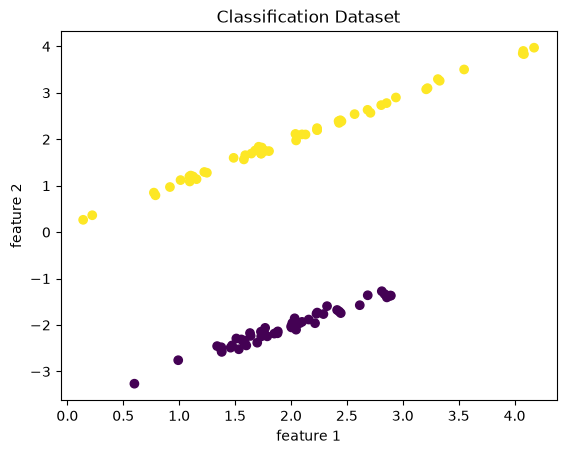

In [57]:
plt.scatter(X[:, 0], X[:, 1], c=y)

plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.title("Classification Dataset")

plt.show()

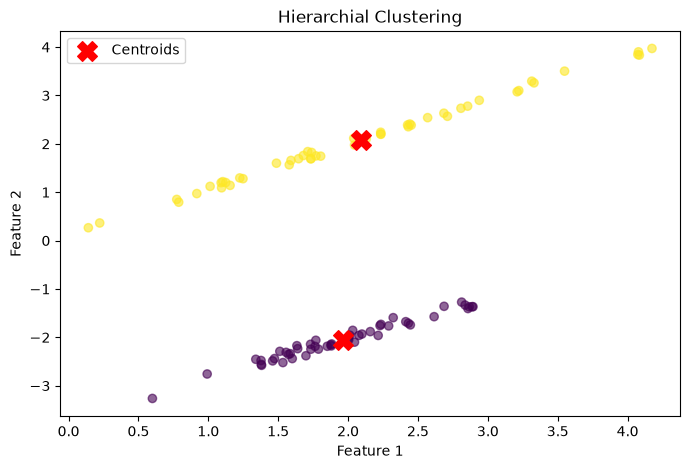

In [58]:
assignments, clusters = hierarchical_bottom_up_optimized(X, k=2)

final_centroids = np.zeros((len(clusters), X.shape[1]))

for i in range(len(clusters)):
    final_centroids[i] = np.mean(X[clusters[i]], axis=0)

plt.figure(figsize=(8, 5))
scatter = plt.scatter(X[:, 0], X[:, 1], c=assignments, cmap='viridis', alpha=0.6)
plt.scatter(final_centroids[:, 0], final_centroids[:, 1], 
            marker="X", s=200, c='red', label="Centroids")

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Hierarchial Clustering")
plt.legend()
plt.show()

In [59]:
df = pd.read_csv('mall_seg/Mall_Customers.csv')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [60]:
df.drop(columns=['CustomerID'], inplace=True)

In [61]:
df['Gender'] = df['Gender'].map({'Male': 0, 'Female': 1})

In [62]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaler.fit_transform(df)
X = df.values

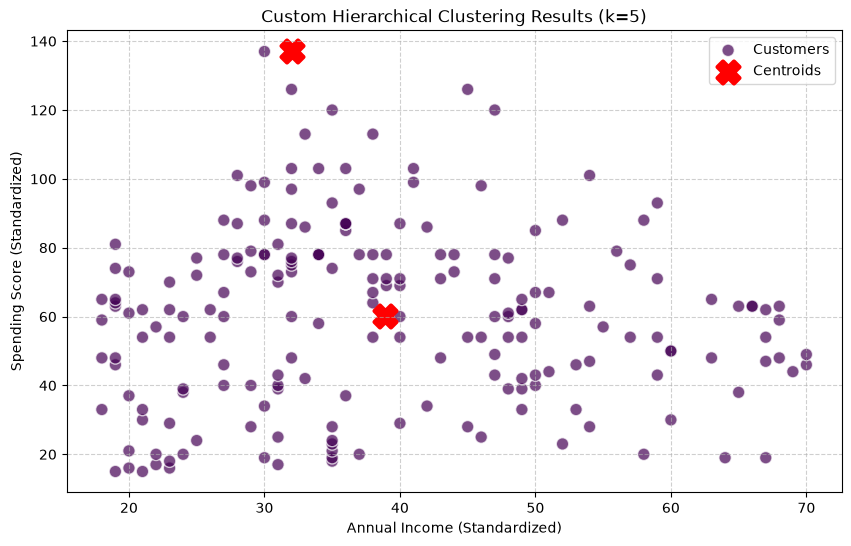

In [65]:
labels, clusters = hierarchical_bottom_up_optimized(X, k=2)

centroids = np.zeros((len(clusters), X.shape[1]))

for i in range(len(clusters)):
    centroids[i] = np.mean(X[clusters[i]], axis=0)

plt.figure(figsize=(10, 6))

plt.scatter(
    X[:, 1], 
    X[:, 2], 
    c=labels,  
    alpha=0.7, 
    edgecolors='w', 
    s=80, 
    label='Customers'
)

plt.scatter(
    centroids[:, 1], 
    centroids[:, 2], 
    c='red', 
    marker='X', 
    s=250, 
    linewidths=3,
    label='Centroids'
)

plt.title('Custom Hierarchical Clustering Results (k=5)')
plt.xlabel('Annual Income (Standardized)')
plt.ylabel('Spending Score (Standardized)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()